## Dependencies

**Note**: This notebook now uses the `generative_eeg_augmentation` library for model architectures and data loading.

To install the library (if not already installed):
```bash
cd /Users/rahul/PycharmProjects/GEN_EEG_ONE
uv pip install -e .
```

This eliminates code duplication by importing:
- Model classes: `EEGGenerator`, `EEGDiscriminator` from `generative_eeg_augmentation.models.gan`
- Data loading: `load_all_preprocessed()` from `generative_eeg_augmentation.data.loader`

# Exploratory Notebook: GAN for EEG Data Augmentation


**Overview:**
In this notebook, we:
1. Load preprocessed EEG data (63 channels, ~1001 timepoints per epoch).
2. Define a GAN architecture without conditional labels.
3. Train the GAN using a standard adversarial loss.
4. Visualize the training progress and generated EEG samples (both in time and frequency domains).

**Note:** This GAN does not incorporate class conditioning. It learns to generate EEG-like signals from noise.

**Team Contributions:**
- **Rahul:** Overall project integration, GAN implementation, and documentation.




## Important Note on Library Integration

**This notebook has been updated to work with the conditional GAN models from the `generative_eeg_augmentation` library.**

The library's `EEGGenerator` and `EEGDiscriminator` require **labels** as input (they were designed for conditional GANs). To make this notebook work with the library:

1. **DataLoader includes labels**: The dataset now includes both EEG data and labels
2. **All model calls pass labels**: Both generator and discriminator receive labels during training
3. **Generation uses dummy labels**: When generating samples, we create dummy labels (class 0)

This effectively makes this a **conditional GAN** (conditioned on motor imagery classes), which is actually an improvement over the original simple GAN approach, as it allows for class-specific generation.

In [11]:
# imports
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import welch

# Import from generative_eeg_augmentation library
from generative_eeg_augmentation.models.gan import EEGGenerator, EEGDiscriminator
from generative_eeg_augmentation.data.loader import load_all_preprocessed

# Configure matplotlib and seaborn
%matplotlib inline
sns.set_theme(style="whitegrid", palette="viridis", font_scale=1.2)

# Set random seeds
torch.manual_seed(42)
np.random.seed(42)

In [ ]:
# hyperparameter definition

latent_dim = 100
n_channels = 63

default_target_signal_len = 1001 # this is from data, but we usually take this dynamically
# when loading the data

batch_size = 64
learning_rate = 5e-5
num_epochs = 500  # Increase this for full training

In [13]:
# setting device
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("Using device:", device)

Using device: mps


### Loading data and instantiating models

In [16]:
# Load data using library function
all_data, all_labels = load_all_preprocessed()
print("All data shape:", all_data.shape)
print("Labels shape:", all_labels.shape)

# Convert data to torch tensor (float32)
real_EEG = torch.from_numpy(all_data.astype(np.float32))
real_labels = torch.from_numpy(all_labels.astype(np.float32))
print("Torch EEG data shape:", real_EEG.shape)
print("Torch labels shape:", real_labels.shape)

# Update target_signal_len based on real data
target_signal_len = real_EEG.shape[2]
print("Target signal length from data:", target_signal_len)

# Instantiate models with updated target_signal_len
# Note: Using conditional models from library (require labels)
generator = EEGGenerator(latent_dim=latent_dim, n_channels=n_channels, target_signal_len=target_signal_len).to(device)
discriminator = EEGDiscriminator(n_channels=n_channels, target_signal_len=target_signal_len).to(device)

optimizer_G = optim.Adam(generator.parameters(), lr=learning_rate, betas=(0.5, 0.9))
optimizer_D = optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.9))

# Create DataLoader with labels
dataset = TensorDataset(real_EEG, real_labels)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

Loaded preprocessed EEG data shape: (250, 63, 1001)
Loaded labels shape: (250, 2)
All data shape: (250, 63, 1001)
Labels shape: (250, 2)
Torch EEG data shape: torch.Size([250, 63, 1001])
Torch labels shape: torch.Size([250, 2])
Target signal length from data: 1001


### Training loop for GAN

In [17]:
criterion = nn.BCELoss()

def real_labels_tensor(size):
    return torch.ones(size, 1).to(device)

def fake_labels_tensor(size):
    return torch.zeros(size, 1).to(device)

G_losses = []
D_losses = []

print("Starting training of simple GAN...")
print("Note: Using conditional models from library (passing labels to generator/discriminator)")

for epoch in tqdm(range(num_epochs), desc="Epochs"):
    for i, (real_batch, batch_labels) in enumerate(dataloader):
        real_batch = real_batch.to(device)
        batch_labels = batch_labels.to(device)
        current_batch_size = real_batch.size(0)

        # ---------------------
        #  Train Discriminator
        # ---------------------
        optimizer_D.zero_grad()

        # Real EEG labels (target 1)
        real_targets = real_labels_tensor(current_batch_size)
        D_real = discriminator(real_batch, batch_labels)
        loss_real = criterion(D_real, real_targets)

        # Generate fake EEG
        noise = torch.randn(current_batch_size, latent_dim).to(device)
        fake_EEG = generator(noise, batch_labels)
        fake_targets = fake_labels_tensor(current_batch_size)
        D_fake = discriminator(fake_EEG.detach(), batch_labels)
        loss_fake = criterion(D_fake, fake_targets)

        D_loss = loss_real + loss_fake
        D_loss.backward()
        optimizer_D.step()

        # -----------------
        #  Train Generator
        # -----------------
        optimizer_G.zero_grad()
        # For generator, we want the discriminator to label the fake EEG as real (target 1)
        D_fake_for_G = discriminator(fake_EEG, batch_labels)
        G_loss = criterion(D_fake_for_G, real_targets)
        G_loss.backward()
        optimizer_G.step()

        G_losses.append(G_loss.item())
        D_losses.append(D_loss.item())

    if (epoch+1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}] | D_loss: {D_loss.item():.4f} | G_loss: {G_loss.item():.4f}")

print("Training complete.")

Starting training of simple GAN...
Note: Using conditional models from library (passing labels to generator/discriminator)


Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Training complete.


### Visualisations

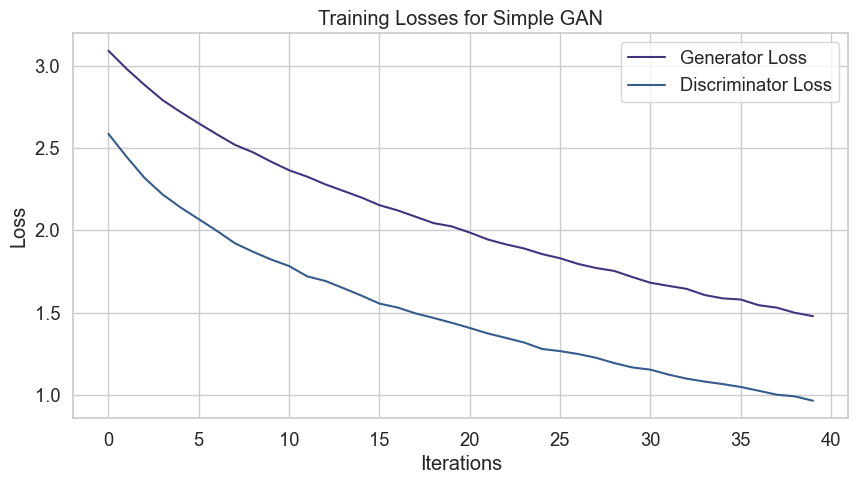

In [18]:
plt.figure(figsize=(10,5))
plt.plot(G_losses, label="Generator Loss")
plt.plot(D_losses, label="Discriminator Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Training Losses for Simple GAN")
plt.legend()
plt.show()

In [19]:
# Generation and vis of synthetic data

def generate_samples(generator, num_samples):
    noise = torch.randn(num_samples, latent_dim).to(device)
    # Create dummy labels (class 0) for generation
    dummy_labels = torch.zeros(num_samples, 2).to(device)
    dummy_labels[:, 0] = 1  # Set first class
    with torch.no_grad():
        fake_samples = generator(noise, dummy_labels)
    return fake_samples.cpu().numpy()

# Generate 4 samples
fake_samples = generate_samples(generator, 4)

/var/folders/3j/w0qrc74d6sj7fjdwc593xcqc0000gn/T/ipykernel_19106/1900427219.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="upper right", fontsize="small")


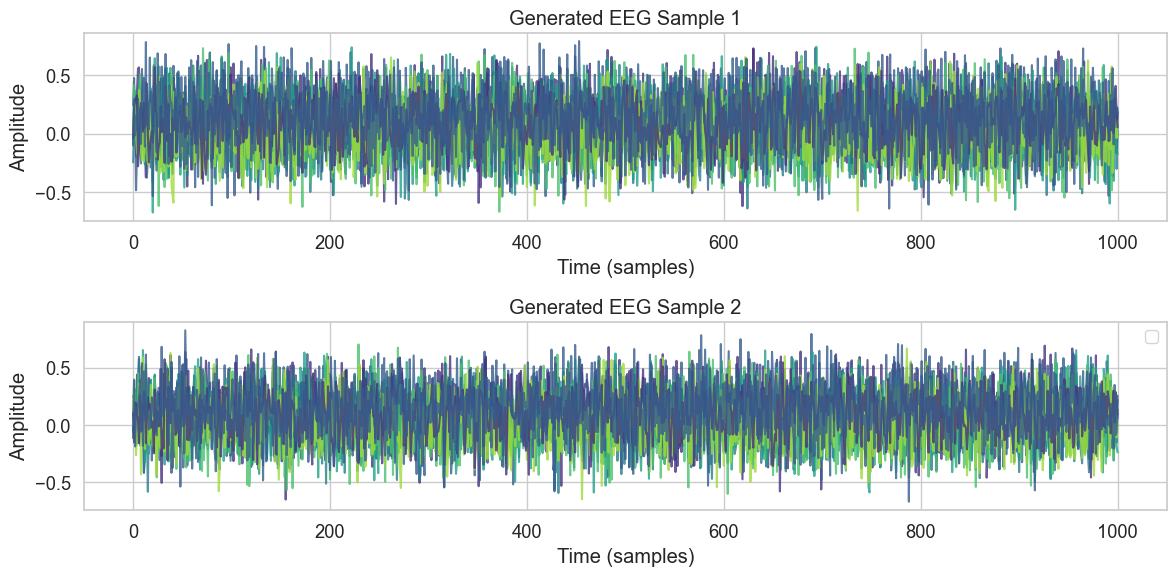

In [20]:
num_to_plot = 2
plt.figure(figsize=(12, 6))
for i in range(num_to_plot):
    plt.subplot(num_to_plot, 1, i+1)
    for ch in range(8):
        plt.plot(fake_samples[i, ch, :], label=f"Ch {ch}" if i == 0 else "", alpha=0.8)
    plt.title(f"Generated EEG Sample {i+1}")
    plt.xlabel("Time (samples)")
    plt.ylabel("Amplitude")
plt.tight_layout()
plt.legend(loc="upper right", fontsize="small")
plt.show()

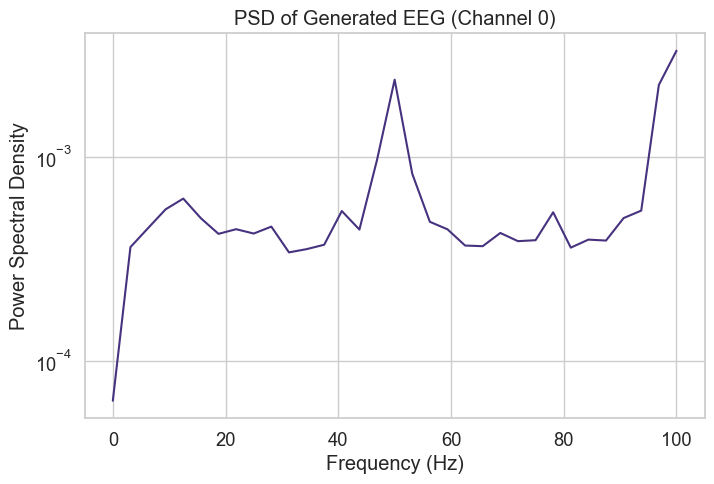

In [21]:
# PSD

fs_generated = 200  # Sampling frequency
sample_idx = 0
channel_idx = 0
signal_data = fake_samples[sample_idx, channel_idx, :]

freqs, psd = welch(signal_data, fs=fs_generated, nperseg=64)

plt.figure(figsize=(8,5))
plt.semilogy(freqs, psd)
plt.title("PSD of Generated EEG (Channel 0)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.show()